# Análisis de enlaces de Wikipedia (inglés): PageRank, HITS y PageRank sensible a tópico

**Datos:** `enwiki-latest-pages-articles-multistream.xml` (~118 GB sin comprimir).

**Pipeline** (los pasos pesados se ejecutan como scripts fuera del notebook):
1. `src/extract_links.py` — parseo en streaming y en paralelo del XML (rangos de bytes, 12 procesos). Solo artículos (`ns=0`): títulos, redirecciones, enlaces `[[...]]` y categorías → Parquet.
2. `src/build_graph.py` — resolución de redirecciones, mapeo título→índice, deduplicación → lista de aristas `src → dst`.
3. **Este notebook** — matrices dispersas CSR (SciPy) e implementación propia de los algoritmos por iteración de potencia.

> Con 16 GB de RAM y millones de nodos no es viable NetworkX sobre el grafo completo; se usa solo para validar las implementaciones en un subgrafo pequeño.

In [1]:
import time, re
import numpy as np, scipy.sparse as sp, polars as pl
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr, kendalltau
sns.set_theme(style="whitegrid")
pl.Config.set_tbl_rows(20); pl.Config.set_fmt_str_lengths(60)

GRAPH_DIR = "../data/graph"
BETA, TOL, MAX_IT = 0.85, 1e-9, 200

## 1. Carga del grafo

In [2]:
t = time.time()
nodes = pl.read_parquet(f"{GRAPH_DIR}/nodes.parquet")
E = pl.read_parquet(f"{GRAPH_DIR}/edges.parquet")
src, dst = E["src"].to_numpy().astype(np.int32), E["dst"].to_numpy().astype(np.int32)
del E
N, M = nodes.height, len(src)
# A[i, j] = 1 si i enlaza a j
A = sp.csr_array((np.ones(M, np.float32), (src, dst)), shape=(N, N))
AT = A.T.tocsr()
del src, dst
out_deg = np.asarray(A.sum(axis=1)).ravel()
in_deg = np.asarray(AT.sum(axis=1)).ravel()
titles = nodes["title"].to_numpy()
print(f"N = {N:,} artículos | M = {M:,} enlaces | {time.time()-t:.0f}s")
print(f"grado medio = {M/N:.1f} | nodos colgantes (sin salida) = {(out_deg==0).sum():,} | sin entrada = {(in_deg==0).sum():,}")

N = 7,249,098 artículos | M = 236,203,272 enlaces | 21s
grado medio = 32.6 | nodos colgantes (sin salida) = 7,647 | sin entrada = 457,593


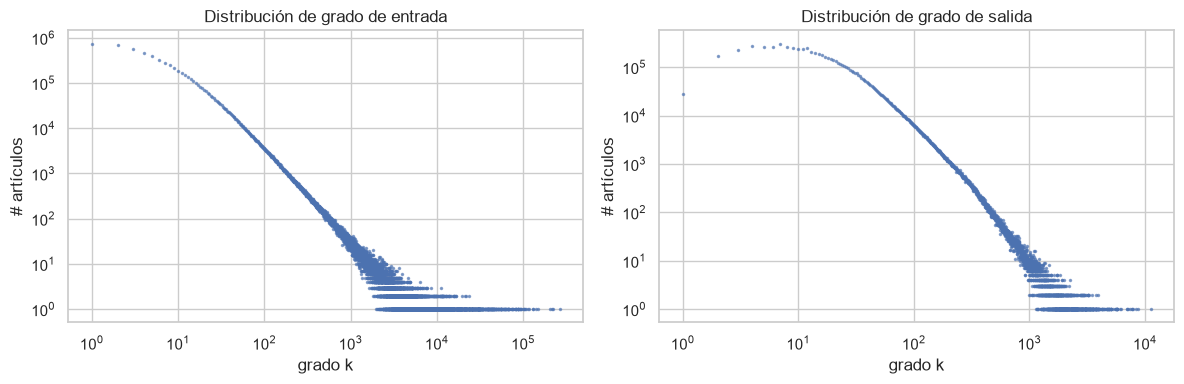

rank,título,grado_entrada
i64,str,f32
1,"""Association football""",264883.0
2,"""World War II""",220972.0
3,"""United States""",218772.0
4,"""The New York Times""",203663.0
5,"""New York City""",149464.0
6,"""France""",141780.0
7,"""London""",130318.0
8,"""AllMusic""",129358.0
9,"""World War I""",118263.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, d, name in [(axes[0], in_deg, "entrada"), (axes[1], out_deg, "salida")]:
    vals, cnt = np.unique(d[d > 0].astype(np.int64), return_counts=True)
    ax.loglog(vals, cnt, ".", ms=3, alpha=.6)
    ax.set(title=f"Distribución de grado de {name}", xlabel="grado k", ylabel="# artículos")
plt.tight_layout(); plt.show()

def top(scores, k=20, label="score"):
    idx = np.argsort(-scores)[:k]
    return pl.DataFrame({"rank": np.arange(1, k+1), "título": titles[idx], label: scores[idx]})

top(in_deg, label="grado_entrada")

## 2. PageRank

Iteración de potencia sobre la matriz estocástica por columnas $M_{ji} = 1/ \text{out}(i)$ si $i \to j$:

$$r^{(t+1)} = \beta, M r^{(t)} + \big(\beta, d^\top r^{(t)} + 1-\beta\big), v$$

donde $d$ marca los nodos colgantes (su masa se redistribuye según $v$) y $v$ es el vector de teletransporte. Para PageRank clásico $v = \mathbf{1}/N$; para el sensible a tópico $v$ es uniforme sobre el conjunto del tópico $S$ (así ambos casos usan la misma función).

In [4]:
dangling = out_deg == 0
inv_out = np.where(dangling, 0, 1.0 / np.maximum(out_deg, 1)).astype(np.float64)

def pagerank(v=None, beta=BETA, tol=TOL, max_it=MAX_IT, verbose=True):
    v = np.full(N, 1.0 / N) if v is None else v / v.sum()
    r = v.copy()
    for it in range(1, max_it + 1):
        r_new = beta * (AT @ (r * inv_out))
        r_new += (beta * r[dangling].sum() + 1 - beta) * v
        err = np.abs(r_new - r).sum()
        r = r_new
        if err < tol:
            break
    if verbose: print(f"convergió en {it} iteraciones (L1 = {err:.2e}), suma = {r.sum():.6f}")
    return r

t = time.time(); pr = pagerank(); print(f"{time.time()-t:.0f}s")
top(pr, 25, "pagerank")

convergió en 62 iteraciones (L1 = 7.88e-10), suma = 1.000000
186s


rank,título,pagerank
i64,str,f64
1,"""United States""",0.000929
2,"""The New York Times""",0.000879
3,"""World War II""",0.00084
4,"""Association football""",0.000727
5,"""France""",0.00059
6,"""United Kingdom""",0.000533
7,"""New York City""",0.000523
8,"""The Guardian""",0.000474
9,"""Germany""",0.000471


## 3. HITS (hubs y autoridades)

$a \leftarrow A^\top h$, $h \leftarrow A a$, normalizando en cada paso. Converge a los vectores propios principales de $A^\top A$ (autoridades) y $A A^\top$ (hubs).

Lo aplicamos de dos formas: **(a)** global sobre todo el grafo y **(b)** en su forma original de Kleinberg, dependiente de una consulta: conjunto raíz + vecinos (conjunto base).

In [5]:
def hits(A, AT, tol=1e-8, max_it=MAX_IT, verbose=True):
    n = A.shape[0]
    h = np.full(n, 1 / np.sqrt(n))
    for it in range(1, max_it + 1):
        a = AT @ h; a /= np.linalg.norm(a)
        h_new = A @ a; h_new /= np.linalg.norm(h_new)
        err = np.abs(h_new - h).sum(); h = h_new
        if err < tol: break
    if verbose: print(f"HITS convergió en {it} iteraciones (L1 = {err:.2e})")
    return h, a

t = time.time(); hub, auth = hits(A, AT); print(f"{time.time()-t:.0f}s")
display(top(auth, 20, "autoridad")); display(top(hub, 20, "hub"))

HITS convergió en 123 iteraciones (L1 = 8.41e-09)
724s


rank,título,autoridad
i64,str,f64
1,"""The New York Times""",0.262893
2,"""United States""",0.226084
3,"""World War II""",0.198866
4,"""New York City""",0.1787
5,"""U.S. state""",0.148029
6,"""The Guardian""",0.129832
7,"""London""",0.118535
8,"""United States Census Bureau""",0.118259
9,"""Geographic Names Information System""",0.117342


rank,título,hub
i64,str,f64
1,"""Demonym""",0.012894
2,"""2025 in the United States""",0.012625
3,"""List of University of Pennsylvania people""",0.012386
4,"""May 1982""",0.012028
5,"""2020s""",0.011885
6,"""List of enclaves and exclaves""",0.011747
7,"""List of art museums""",0.011656
8,"""21st century""",0.011373
9,"""2000s""",0.011141


Observación esperada: el HITS global suele quedar dominado por una comunidad densa (*tightly-knit community effect*) — las autoridades/hubs top no son necesariamente las páginas “más importantes”, sino las del núcleo más densamente interconectado (p.ej. listas y plantillas de navegación incluidas en el texto).

## 4. PageRank sensible a tópico

Cada tópico se define por un conjunto de teletransporte $S$: artículos cuyas categorías coinciden con una expresión regular. $v_i = 1/|S|$ si $i\\in S$, 0 si no.

In [6]:
cats = pl.read_parquet(f"{GRAPH_DIR}/cats.parquet")
print(f"{cats.height:,} pares (artículo, categoría), {cats['category'].n_unique():,} categorías distintas")

TOPICS = {
    "Matemáticas":  r"(?i)\bmathemat|\btheorems?\b|\balgebra|\bgeometry\b|number theory",
    "Física":       r"(?i)\bphysics\b|\bphysicists\b|quantum|thermodynamics",
    "Computación":  r"(?i)computer science|programming languages|\balgorithms\b|software engineering|artificial intelligence",
    "Música":       r"(?i)\bmusic(al)? genres|\bmusicians\b|\bsingers\b|\bcomposers\b|\bbands\b",
    "Deportes":     r"(?i)\bfootball\b|\bbasketball\b|\bolympic|\bsports\b|\btennis\b",
    "Biología":     r"(?i)\bbiology\b|\bgenetics\b|\bevolution\b|\bbotany\b|\bzoology\b|\becology\b",
}
topic_sets = {}
for name, rx in TOPICS.items():
    idx = cats.filter(pl.col("category").str.contains(rx))["idx"].unique().to_numpy()
    topic_sets[name] = idx
    print(f"{name:12s} |S| = {len(idx):,}")

42,550,307 pares (artículo, categoría), 1,866,082 categorías distintas
Matemáticas  |S| = 26,547
Física       |S| = 18,462
Computación  |S| = 8,173
Música       |S| = 145,913
Deportes     |S| = 847,566
Biología     |S| = 11,427


In [7]:
tspr = {}
for name, S in topic_sets.items():
    v = np.zeros(N); v[S] = 1.0
    t = time.time(); tspr[name] = pagerank(v, verbose=False); print(f"{name}: {time.time()-t:.0f}s")

K = 15
pl.DataFrame({name: titles[np.argsort(-r)[:K]] for name, r in tspr.items()}).with_row_index("rank", 1)

Matemáticas: 54s
Física: 83s
Computación: 52s
Música: 49s
Deportes: 52s
Biología: 359s


rank,Matemáticas,Física,Computación,Música,Deportes,Biología
u32,str,str,str,str,str,str
1,"""Mathematics""","""Physics""","""Computer science""","""The New York Times""","""Association football""","""Protein"""
2,"""Mathematician""","""American Physical Society""","""Artificial intelligence""","""AllMusic""","""Midfielder""","""Gene"""
3,"""Springer Science+Business Media""","""Physicist""","""Algorithm""","""United States""","""Defender (association football)""","""Academic journal"""
4,"""American Mathematical Society""","""Mathematics""","""The New York Times""","""New York City""","""Forward (association football)""","""DNA"""
5,"""Real number""","""World War II""","""Mathematics""","""Jazz""","""United States""","""Peer review"""
6,"""Cambridge University Press""","""Quantum mechanics""","""Programming language""","""World War II""","""World War II""","""United States"""
7,"""Academic journal""","""The New York Times""","""United States""","""Billboard (magazine)""","""Basketball""","""The New York Times"""
8,"""United States""","""United States""","""Academic journal""","""The Guardian""","""The New York Times""","""Enzyme"""
9,"""The New York Times""","""Doctor of Philosophy""","""Association for Computing Machinery""","""London""","""American football""","""Bacteria"""


**Combinación por consulta:** dada una consulta con probabilidades por tópico $P(\text{tópico}\mid q)$, el ranking es $\sum_k P(k\mid q)\, r_k$ — se precalculan los vectores y se combinan en tiempo de consulta.

In [8]:
def query_rank(weights, k=15):
    w = np.array([weights.get(n, 0) for n in tspr]); w = w / w.sum()
    return top(sum(wi * tspr[n] for wi, n in zip(w, tspr)), k, "score")

query_rank({"Matemáticas": 0.6, "Computación": 0.4})

rank,título,score
i64,str,f64
1,"""Mathematics""",0.002865
2,"""Computer science""",0.001062
3,"""Mathematician""",0.001052
4,"""Springer Science+Business Media""",0.000958
5,"""United States""",0.000828
6,"""The New York Times""",0.000821
7,"""Academic journal""",0.000807
8,"""American Mathematical Society""",0.000753
9,"""Artificial intelligence""",0.000748


## 5. HITS dependiente de consulta (Kleinberg)
Conjunto raíz = artículos del tópico; conjunto base = raíz ∪ sucesores ∪ (hasta 50) predecesores por nodo.

In [9]:
rng = np.random.default_rng(0)
def base_set(root, max_pred=50):
    succ = A[root].indices if len(root) else np.array([], int)
    sub = AT[root]
    preds = [ (p if len(p) <= max_pred else rng.choice(p, max_pred, replace=False))
              for p in np.split(sub.indices, sub.indptr[1:-1]) ]
    return np.unique(np.concatenate([root, succ, *preds]))

for name in ["Matemáticas", "Música"]:
    B = base_set(topic_sets[name])
    sub = A[B][:, B].tocsr()
    h, a = hits(sub, sub.T.tocsr(), verbose=False)
    print(f"\n{name}: conjunto base = {len(B):,} nodos, {sub.nnz:,} aristas")
    ia, ih = np.argsort(-a)[:10], np.argsort(-h)[:10]
    display(pl.DataFrame({"autoridades": titles[B[ia]], "hubs": titles[B[ih]]}).with_row_index("rank", 1))


Matemáticas: conjunto base = 227,710 nodos, 9,684,555 aristas


rank,autoridades,hubs
u32,str,str
1,"""The New York Times""","""21st century"""
2,"""World War II""","""List of University of Pennsylvania people"""
3,"""The Guardian""","""1945"""
4,"""United States""","""2014 in the United States"""
5,"""Catholic Church""","""2000s"""
6,"""World War I""","""1944"""
7,"""New York City""","""United States"""
8,"""The Washington Post""","""May 1982"""
9,"""Soviet Union""","""2020 in the United States"""



Música: conjunto base = 1,236,147 nodos, 57,060,012 aristas


rank,autoridades,hubs
u32,str,str
1,"""AllMusic""","""2000s"""
2,"""Billboard (magazine)""","""Graduation (album)"""
3,"""The New York Times""","""Ariana Grande"""
4,"""The Guardian""","""Lady Gaga"""
5,"""Rolling Stone""","""Lemonade (album)"""
6,"""YouTube""","""Usher (musician)"""
7,"""Los Angeles Times""","""The Life of a Showgirl"""
8,"""New York City""","""Cultural impact of Taylor Swift"""
9,"""Billboard Hot 100""","""Miley Cyrus"""


## 6. Comparación de rankings

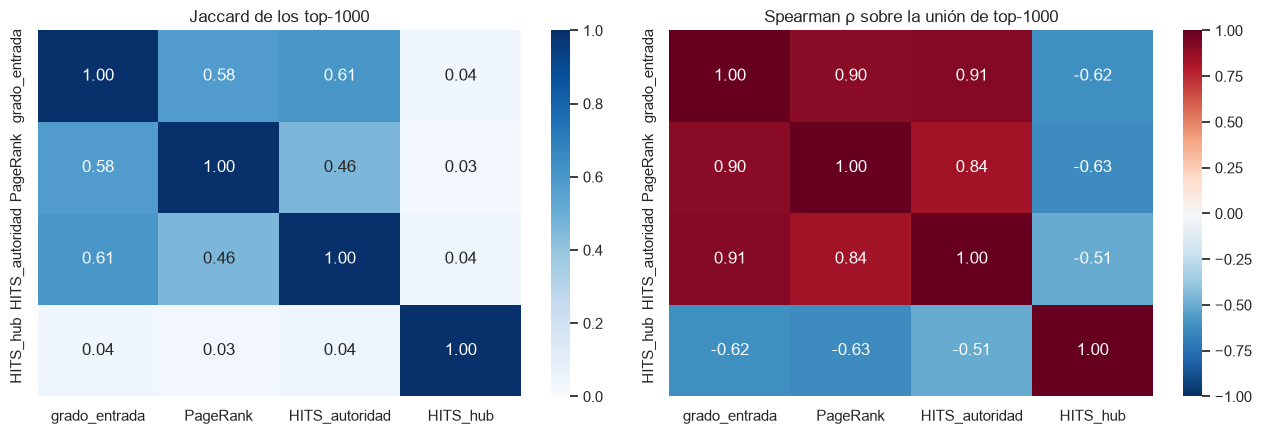

In [10]:
K = 1000
measures = {"grado_entrada": in_deg.astype(float), "PageRank": pr, "HITS_autoridad": auth, "HITS_hub": hub}
names = list(measures)
tops = {n: set(np.argsort(-s)[:K]) for n, s in measures.items()}
jac = np.array([[len(tops[a] & tops[b]) / len(tops[a] | tops[b]) for b in names] for a in names])
# correlación de rangos sobre la unión de los top-K
U = np.array(sorted(set().union(*tops.values())))
rho = np.array([[spearmanr(measures[a][U], measures[b][U])[0] for b in names] for a in names])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(jac, annot=True, fmt=".2f", xticklabels=names, yticklabels=names, cmap="Blues", ax=ax[0], vmin=0, vmax=1)
ax[0].set_title(f"Jaccard de los top-{K}")
sns.heatmap(rho, annot=True, fmt=".2f", xticklabels=names, yticklabels=names, cmap="RdBu_r", ax=ax[1], vmin=-1, vmax=1)
ax[1].set_title(f"Spearman ρ sobre la unión de top-{K}")
plt.tight_layout(); plt.show()

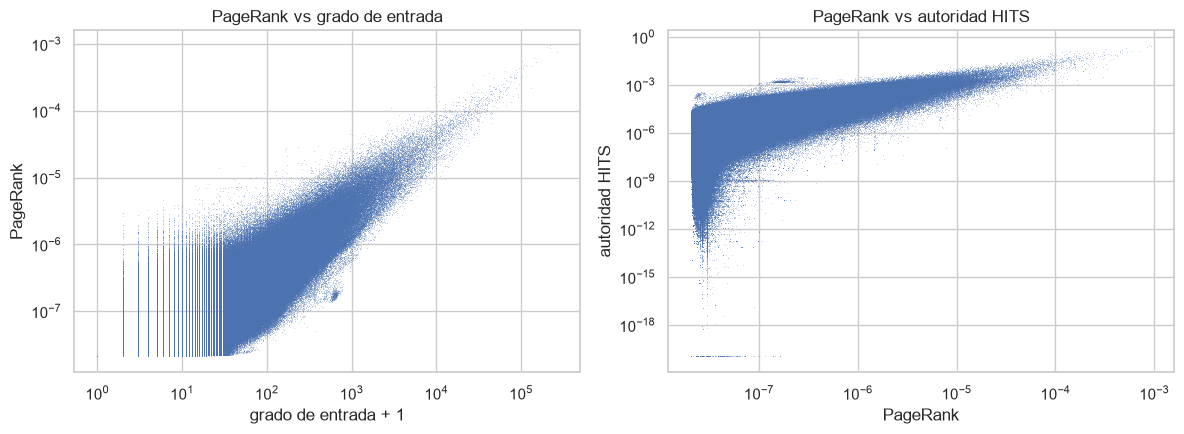

{'Matemáticas': 21, 'Física': 27, 'Computación': 21, 'Música': 55, 'Deportes': 44, 'Biología': 26} ← artículos compartidos con el top-100 general


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].loglog(in_deg + 1, pr, ",", alpha=.3); ax[0].set(xlabel="grado de entrada + 1", ylabel="PageRank", title="PageRank vs grado de entrada")
ax[1].loglog(pr, auth + 1e-20, ",", alpha=.3); ax[1].set(xlabel="PageRank", ylabel="autoridad HITS", title="PageRank vs autoridad HITS")
plt.tight_layout(); plt.show()

# Cuánto se mueve cada tópico respecto al PageRank general (top-100)
gen = set(np.argsort(-pr)[:100])
print({n: len(gen & set(np.argsort(-r)[:100])) for n, r in tspr.items()}, "← artículos compartidos con el top-100 general")

In [ ]:
# Sensibilidad a beta (factor de amortiguamiento)
res = {}
for b in [0.5, 0.7, 0.85, 0.95]:
    t = time.time(); r = pagerank(beta=b, verbose=False)
    res[b] = r; print(f"β={b}: {time.time()-t:.0f}s")
ref = set(np.argsort(-res[0.85])[:100])
print({b: len(ref & set(np.argsort(-r)[:100])) for b, r in res.items()}, "← solapamiento top-100 con β=0.85")

β=0.5: 24s
β=0.7: 37s
β=0.85: 60s
β=0.95: 209s
{0.5: 76, 0.7: 85, 0.85: 100, 0.95: 80} ← solapamiento top-100 con β=0.85


## 7. Validación contra NetworkX (subgrafo pequeño)

In [13]:
import networkx as nx
S = np.argsort(-in_deg)[:3000]
sub = A[S][:, S].tocoo()
G = nx.DiGraph(); G.add_nodes_from(range(len(S))); G.add_edges_from(zip(sub.row, sub.col))
# nuestras funciones sobre el subgrafo
_A, _AT = sub.tocsr(), sub.T.tocsr()
_od = np.asarray(_A.sum(1)).ravel(); _dg = _od == 0; _io = np.where(_dg, 0, 1/np.maximum(_od, 1))
n = len(S); r = np.full(n, 1/n)
for _ in range(500):
    r = BETA * (_AT @ (r * _io)) + (BETA * r[_dg].sum() + 1 - BETA) / n
nx_pr = nx.pagerank(G, alpha=BETA, tol=1e-12, max_iter=500)
h, a = hits(_A, _AT, verbose=False)
nx_h, nx_a = nx.hits(G, max_iter=1000, tol=1e-12)
print("PageRank  max |Δ| =", np.abs(r - np.array([nx_pr[i] for i in range(n)])).max())
print("Autoridad Spearman ρ =", spearmanr(a, [nx_a[i] for i in range(n)])[0])

PageRank  max |Δ| = 3.917272001566219e-10
Autoridad Spearman ρ = 0.9999999999999999


## 8. Conclusiones
Se eligió el pipeline descrito ya que el dataset pesa 118Gb y contamos con recursos de RAM limitados 16 GB. Ejecutar los pasos pesados como scripts independientes que guardan los resultados intermedios en parquets permittió que el notebook presente arranque en segundos sin la necesidad de procesar el XML cada vez.
A partir de la ejecución de los scripts y el notebook presente, podemos concluir que: 
- **PageRank** premia artículos citados por muchos artículos *importantes*; su top coincide en gran parte con el grado de entrada pero corrige páginas infladas por plantillas/listas.
- **HITS global** se concentra en el núcleo más denso del grafo (efecto de comunidad), por eso difiere mucho de PageRank; su versión dependiente de consulta da resultados más interpretables (autoridades = artículos centrales del tema, hubs = listas/índices).
- **PageRank sensible a tópico** mantiene la robustez de PageRank pero sesga el teletransporte, mostrando los artículos centrales de cada dominio; los vectores precalculados se combinan linealmente por consulta.
- Escalabilidad: todo cabe en memoria como CSR (`int32` + `float32`); cada iteración es un producto matriz-vector disperso, O(M).